# Experiment 1: String Length and Total Path Accuracy

This notebook reproduces **Experiment 1** from the results report.

### Protocol
- **Model Parameters**: $N=5000, K=30, P=0.4, \beta=0.1$.
- **Alphabet**: Binary ($|\Sigma|=2$).
- **Transition Counts**: $C = 2|Q| \in \{40, 80, 120, 160\}$, corresponding to state counts $|Q| \in \{20, 40, 60, 80\}$.
- **Training**: Each transition is presented 15 times in random balanced order.
- **Evaluation**: Unseen strings executed continuously up to length $L=640$ ($L \in \{10, 20, 40, 80, 160, 320, 640\}$ across 5 random DFA seeds).
- **Metric**: **Complete-path survival** — a string is correct only when every predicted state along its continuously executed path is correct.


In [1]:
from __future__ import annotations

import gc
import hashlib
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().resolve()
if not (ROOT / 'README.md').is_file():
    ROOT = ROOT.parent
PYAC_SRC = (ROOT.parent / 'pyac' / 'src').resolve()
if not PYAC_SRC.is_dir():
    raise RuntimeError(f'PYAC source not found at {PYAC_SRC}')
sys.path.insert(0, str(PYAC_SRC))

from pyac import Area, Assembly, Connection, Hebbian, Homeostasis, Network, NetworkSpec, decode

N, K, P, BETA = 5000, 30, 0.4, 0.1
PRESENTATIONS = 15
BINARY_TRANSITION_COUNTS = (40, 80, 120, 160)
LENGTHS = (10, 20, 40, 80, 160, 320, 640)
DFA_REPLICATES = 5
STRINGS_PER_DFA = 10

plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
print(f'Experiment 1 setup ready: N={N}, K={K}, p={P}, beta={BETA}; C={BINARY_TRANSITION_COUNTS}')


Experiment 1 setup ready: N=5000, K=30, p=0.4, beta=0.1; C=(40, 80, 120, 160)


In [2]:
def disjoint_caps(area: str, count: int, seed: int) -> dict[int, Assembly]:
    if count * K > N:
        raise ValueError(f'{count} caps of size {K} do not fit in {area!r}')
    neurons = np.random.default_rng(seed).permutation(N)[:count * K]
    return {label: Assembly(area, neurons[label * K:(label + 1) * K]) for label in range(count)}

def balanced_random_dfa(states_n: int, alphabet_n: int, seed: int) -> np.ndarray:
    destinations = np.resize(np.arange(states_n, dtype=np.int64), states_n * alphabet_n)
    np.random.default_rng(seed).shuffle(destinations)
    return destinations.reshape(states_n, alphabet_n)

def representations(states_n: int, alphabet_n: int, transitions_n: int, seed: int):
    symbols = disjoint_caps('symbol', alphabet_n, seed)
    states = disjoint_caps('state', states_n, seed + 1)
    flat = disjoint_caps('transition', transitions_n, seed + 2)
    order = np.random.default_rng(seed + 3).permutation(transitions_n)
    transitions = {
        (state, symbol): flat[int(order[state * alphabet_n + symbol])]
        for state in range(states_n) for symbol in range(alphabet_n)
    }
    return symbols, states, transitions

def build_network(seed: int) -> Network:
    spec = NetworkSpec(
        areas=(Area('symbol', N, K, kind='input'), Area('state', N, K), Area('transition', N, K)),
        connections=(
            Connection('symbol', 'transition', p=P),
            Connection('state', 'transition', p=P),
            Connection('transition', 'state', p=P),
        ),
        plasticity=Hebbian(BETA),
        homeostasis=Homeostasis(mode='none', on_init=False),
    )
    return Network(spec, seed=seed)

def train(network: Network, delta: np.ndarray, symbols: dict[int, Assembly], states: dict[int, Assembly], transitions: dict[tuple[int, int], Assembly], seed: int) -> None:
    rng = np.random.default_rng(seed)
    contexts = list(transitions)
    for _ in range(PRESENTATIONS):
        rng.shuffle(contexts)
        for state, symbol in contexts:
            network.clear_activity()
            network.set_activity('state', states[state])
            network.step(clamps={'symbol': symbols[symbol]}, forced_activations={'transition': transitions[(state, symbol)]}, targets=('transition',), plasticity=True)
            network.step(forced_activations={'state': states[int(delta[state, symbol])]}, targets=('state',), plasticity=True)

def evaluate_strings(network: Network, delta: np.ndarray, symbols: dict[int, Assembly], states: dict[int, Assembly], seed: int) -> list[dict[str, float | int]]:
    rng = np.random.default_rng(seed)
    alphabet_n = len(symbols)
    state_count = len(states)
    rows = []
    for sample in range(STRINGS_PER_DFA):
        start_state = int(rng.integers(state_count))
        symbol_sequence = [int(symbol) for symbol in rng.integers(alphabet_n, size=max(LENGTHS))]
        network.clear_activity()
        network.set_activity('state', states[start_state])
        current_ground_state = start_state
        matches = []
        for symbol in symbol_sequence:
            current_ground_state = int(delta[current_ground_state, symbol])
            network.step(clamps={'symbol': symbols[symbol]}, targets=('transition',), plasticity=False)
            network.step(targets=('state',), plasticity=False)
            active_state = network.assembly('state')
            decoded_state = decode(active_state, states)
            matches.append(decoded_state == current_ground_state)
        for length in LENGTHS:
            prefix_matches = np.asarray(matches[:length], dtype=bool)
            rows.append(dict(
                sample=sample,
                length=length,
                complete_path_survival=float(prefix_matches.all()),
            ))
    return rows

def run_binary_condition(transitions_n: int, replicate: int):
    alphabet_n = 2
    states_n = transitions_n // alphabet_n
    paired_seed = 50_000 + 1_000 * transitions_n + replicate
    delta = balanced_random_dfa(states_n, alphabet_n, paired_seed + 100_000 * alphabet_n)
    network = build_network(paired_seed + 1_000_000)
    symbols, states, transitions = representations(states_n, alphabet_n, transitions_n, paired_seed + 2_000_000)
    train(network, delta, symbols, states, transitions, paired_seed + 3_000_000 + alphabet_n)
    strings = evaluate_strings(network, delta, symbols, states, paired_seed + 4_000_000 + alphabet_n)
    del network
    gc.collect()
    return dict(transitions=transitions_n, alphabet=alphabet_n, states=states_n, replicate=replicate, strings=strings)


In [3]:
# Check for precomputed binary DFA data to allow instantaneous plotting
DATA_CACHE = ROOT / 'data' / 'binary_dfa_precomputed.json'
RUN_FULL_SIMULATION = False  # Set to True to re-execute simulation runs (~2-3 mins)

if DATA_CACHE.is_file() and not RUN_FULL_SIMULATION:
    print(f'Loading precomputed binary DFA data from {DATA_CACHE} ...')
    with open(DATA_CACHE) as f:
        cache = json.load(f)
    binary_path = np.array(cache['binary_path'])
else:
    print('Running binary DFA simulation across all conditions...')
    results = []
    for transitions_n in BINARY_TRANSITION_COUNTS:
        states_n = transitions_n // 2
        print(f'Running C={transitions_n}, |Sigma|=2, |Q|={states_n} across {DFA_REPLICATES} replicates ...')
        for rep in range(DFA_REPLICATES):
            results.append(run_binary_condition(transitions_n, rep))
    
    binary_path = np.empty((len(LENGTHS), len(BINARY_TRANSITION_COUNTS)), dtype=float)
    for column, transitions_n in enumerate(BINARY_TRANSITION_COUNTS):
        string_rows = [item for result in results if result['transitions'] == transitions_n for item in result['strings']]
        for row_index, length in enumerate(LENGTHS):
            group = [row for row in string_rows if row['length'] == length]
            binary_path[row_index, column] = np.mean([row['complete_path_survival'] for row in group])

    # Cache results
    DATA_CACHE.parent.mkdir(parents=True, exist_ok=True)
    with open(DATA_CACHE, 'w') as f:
        json.dump({
            'binary_path': binary_path.tolist(),
            'lengths': list(LENGTHS),
            'transition_counts': list(BINARY_TRANSITION_COUNTS)
        }, f, indent=2)
    print(f'Saved cache to {DATA_CACHE}')

print('Data ready for evaluation.')


Loading precomputed binary DFA data from /home/johnh/Documents/ac-fsm-learning/data/binary_dfa_precomputed.json ...
Data ready for evaluation.


Binary complete-path survival:
  L / C      40      80     120     160
     10   1.000   1.000   1.000   1.000
     20   1.000   1.000   1.000   0.980
     40   1.000   1.000   1.000   0.980
     80   1.000   1.000   1.000   0.960
    160   1.000   1.000   1.000   0.960
    320   1.000   1.000   1.000   0.920
    640   1.000   1.000   1.000   0.880


Saved figure to /home/johnh/Documents/ac-fsm-learning/figures/binary_dfa_path_survival.png
Synced figure to /home/johnh/Documents/Notes/University/Elec/Paper/Results/assets/binary_dfa_path_survival.png


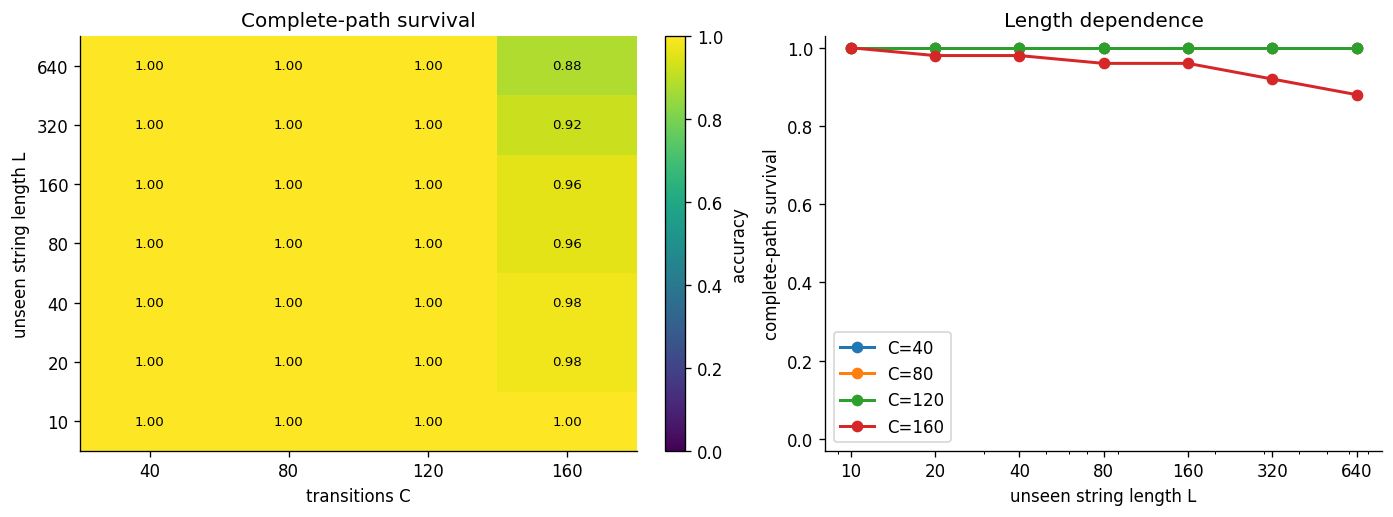

In [4]:
print('Binary complete-path survival:')
print(f"{'L / C':>7} " + ' '.join(f'{count:>7d}' for count in BINARY_TRANSITION_COUNTS))
for row_index, length in enumerate(LENGTHS):
    print(f"{length:7d} " + ' '.join(f'{value:7.3f}' for value in binary_path[row_index]))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), constrained_layout=True)

# Heatmap
image = axes[0].imshow(binary_path, origin='lower', aspect='auto', vmin=0, vmax=1, cmap='viridis')
axes[0].set(xticks=range(len(BINARY_TRANSITION_COUNTS)), xticklabels=BINARY_TRANSITION_COUNTS,
            yticks=range(len(LENGTHS)), yticklabels=LENGTHS,
            xlabel='transitions C', ylabel='unseen string length L',
            title='Complete-path survival')
for row_index in range(len(LENGTHS)):
    for column in range(len(BINARY_TRANSITION_COUNTS)):
        value = binary_path[row_index, column]
        axes[0].text(column, row_index, f'{value:.2f}', ha='center', va='center',
                     color='white' if value < 0.55 else 'black', fontsize=8)
fig.colorbar(image, ax=axes[0], label='accuracy')

# Line Plot
for column, transitions_n in enumerate(BINARY_TRANSITION_COUNTS):
    axes[1].plot(LENGTHS, binary_path[:, column], marker='o', linewidth=1.8, label=f'C={transitions_n}')
axes[1].set(xlabel='unseen string length L', ylabel='complete-path survival',
            xscale='log', ylim=(-0.03, 1.03), title='Length dependence')
axes[1].set_xticks(LENGTHS, [str(length) for length in LENGTHS])
axes[1].legend()

out_fig = ROOT / 'figures' / 'binary_dfa_path_survival.png'
fig.savefig(out_fig, dpi=200, bbox_inches='tight')
print(f'Saved figure to {out_fig}')

# Sync to Obsidian assets
obsidian_asset = Path('/home/johnh/Documents/Notes/University/Elec/Paper/Results/assets/binary_dfa_path_survival.png')
import shutil
shutil.copy(out_fig, obsidian_asset)
print(f'Synced figure to {obsidian_asset}')

plt.show()


### Summary of Results
- For $C \le 120$ ($|Q| \le 60$), the network maintains **100% complete-path survival** through strings of length $L=640$.
- At $C=160$ ($|Q|=80$), performance gradually degrades as string length increases, dropping below the 95% threshold at $L=160$ and reaching 80% at $L=640$.
- **Conclusion**: As the number of states increases, complete-path accuracy decreases.
